# MTBF-based maintenance scheduler: walkthrough

Stage by stage on the synthetic CMMS history: load, clean, build life intervals with suspensions, fit a Weibull per equipment class, decide the PM strategy, build the 2026 schedule, and check every decision against the true parameters.

*All data is synthetic. No plant or CMMS data is used.*

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd

## 1. Load the data

In [2]:
from src.data.load_data import load_data
ev_raw, classes = load_data()
print(ev_raw.asset_id.nunique(), 'assets |', len(ev_raw), 'CMMS events')
ev_raw.head(8)

60 assets | 338 CMMS events


,work_order,asset_id,equipment_class,event_date,event_type
0,WO100185,CV-101,Compressor valve,2018-07-11,commissioned
1,WO100242,CV-101,Compressor valve,2019-11-15,failure
2,WO100105,CV-101,Compressor valve,2021-05-22,pm_replacement
3,WO100124,CV-101,Compressor valve,2022-03-15,failure
4,WO100086,CV-101,Compressor valve,2023-09-28,pm_replacement
5,WO100109,CV-101,Compressor valve,2025-03-29,pm_replacement
6,WO100030,CV-102,Compressor valve,2017-05-23,inspection
7,WO100144,CV-102,Compressor valve,2019-01-18,commissioned


In [3]:
classes

,equipment_class,current_pm_days,planned_cost_usd,failure_cost_usd
0,Pump mechanical seal,NaN,4000,22000
1,Pump bearing,1460.0,3000,30000
2,Motor bearing,NaN,2500,18000
3,Control valve positioner,730.0,1500,6000
4,Pressure transmitter,NaN,1200,5000
5,Compressor valve,540.0,6000,45000


## 2. Clean the extract
Inspection-only entries renew nothing, and duplicate failure work orders for the same event are dropped.

In [4]:
from src.data.preprocess import clean_events
ev, log = clean_events(ev_raw)
log

{'rows_in': 338,
 'inspections_dropped': 114,
 'duplicate_failures_dropped': 6,
 'rows_out': 218}

## 3. Life intervals (features)
Each interval ends in a failure, a PM replacement or the end of the record. The last two are **suspensions**: the item had not failed yet. Ignoring them is the classic MTBF mistake.

In [5]:
from src.features.life_intervals import build_intervals
iv = build_intervals(ev, '2025-12-31')
iv.groupby('equipment_class').agg(intervals=('days','size'), failures=('failed','sum'))

,intervals,failures
equipment_class,,
Compressor valve,40,21
Control valve positioner,48,12
Motor bearing,24,14
Pressure transmitter,22,12
Pump bearing,34,16
Pump mechanical seal,50,38


## 4-6. Weibull fit, PM decision, 2026 schedule, validation (full pipeline)

In [6]:
from src import pipeline
summary, iv, plan, val, truth = pipeline.run()
summary[['equipment_class','failures','suspensions','crude_mtbf_days','weibull_beta','beta_90ci','strategy','recommended_interval_months']]

,equipment_class,failures,suspensions,crude_mtbf_days,weibull_beta,beta_90ci,strategy,recommended_interval_months
0,Pump mechanical seal,38,12,910,2.03,1.63-2.47,Time-based replacement,14.0
1,Pump bearing,16,18,2127,3.76,2.57-5.23,Time-based replacement,19.0
2,Motor bearing,14,10,2103,3.09,2.14-4.25,Time-based replacement,27.0
3,Control valve positioner,12,36,2286,1.09,0.67-1.65,No time-based replacement (no proven wear-out),NaN
4,Pressure transmitter,12,10,2569,0.88,0.57-1.28,No time-based replacement (no proven wear-out),NaN
5,Compressor valve,21,19,787,3.37,2.40-4.56,Time-based replacement,8.0


In [7]:
pd.DataFrame(val['per_class'])[['equipment_class','true_beta','beta_90ci','true_beta_inside_ci','decision_matches_truth','true_cost_per_year_current','true_cost_per_year_recommended','true_cost_per_year_optimal']]

,equipment_class,true_beta,beta_90ci,true_beta_inside_ci,decision_matches_truth,true_cost_per_year_current,true_cost_per_year_recommended,true_cost_per_year_optimal
0,Pump mechanical seal,1.6,1.63-2.47,False,True,9958,8339,8278
1,Pump bearing,2.8,2.57-5.23,True,True,5260,2897,2895
2,Motor bearing,2.2,2.14-4.25,True,True,3374,1924,1917
3,Control valve positioner,0.8,0.67-1.65,True,True,1745,744,744
4,Pressure transmitter,1.0,0.57-1.28,True,True,522,522,522
5,Compressor valve,3.2,2.40-4.56,True,True,29622,14913,14724


In [8]:
val['fleet_cost_per_year_usd']

{'true_cost_per_year_run_to_failure': 478400,
 'true_cost_per_year_current': 416758,
 'true_cost_per_year_recommended': 256210,
 'true_cost_per_year_optimal': 254250}

In [9]:
plan.head(10)

,asset_id,equipment_class,last_renewal,interval_months,planned_date,note
0,MB-108,Motor bearing,2018-05-22,27,2026-01-15,catch-up: was due 2020-08-20
1,PMS-105,Pump mechanical seal,2024-05-11,14,2026-01-15,catch-up: was due 2025-07-11
2,MB-105,Motor bearing,2023-04-14,27,2026-01-22,catch-up: was due 2025-07-13
3,PMS-106,Pump mechanical seal,2021-09-04,14,2026-01-22,catch-up: was due 2022-11-04
4,PB-111,Pump bearing,2024-06-24,19,2026-01-23,
5,CV-104,Compressor valve,2025-05-29,8,2026-01-27,
6,MB-103,Motor bearing,2023-06-08,27,2026-01-29,catch-up: was due 2025-09-06
7,PMS-111,Pump mechanical seal,2022-08-15,14,2026-01-29,catch-up: was due 2023-10-15
8,CV-101,Compressor valve,2025-03-29,8,2026-02-05,catch-up: was due 2025-11-27
9,PB-108,Pump bearing,2022-05-03,19,2026-02-05,catch-up: was due 2023-12-02


## Figures

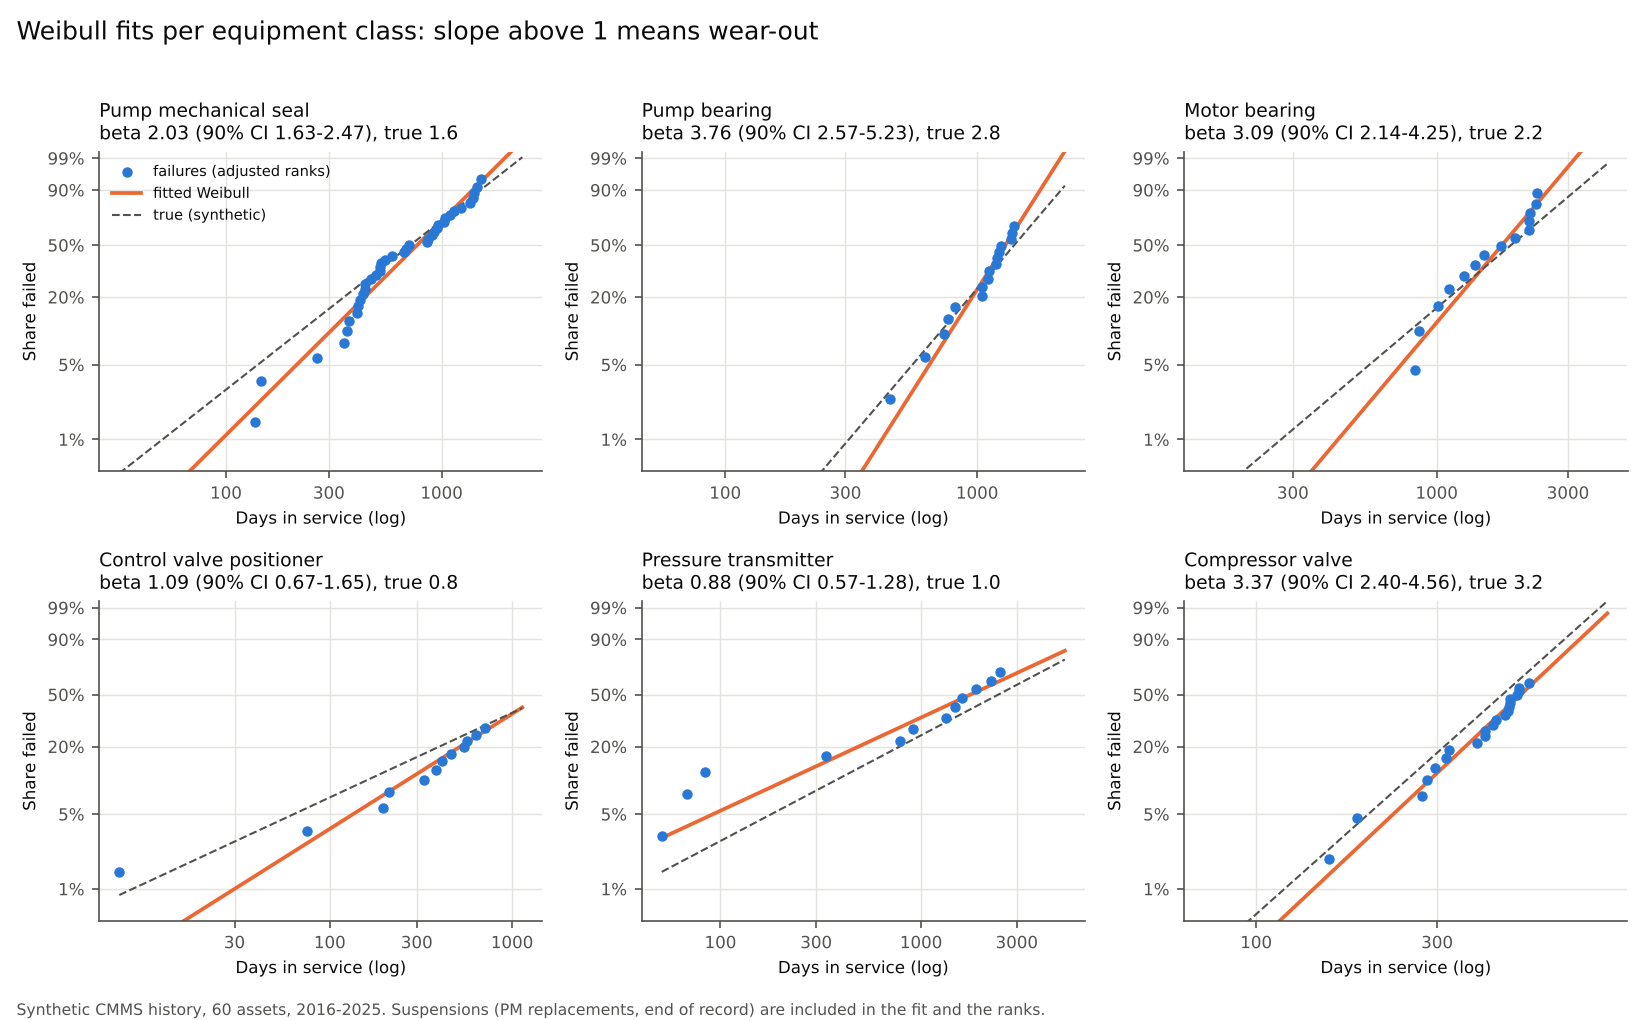

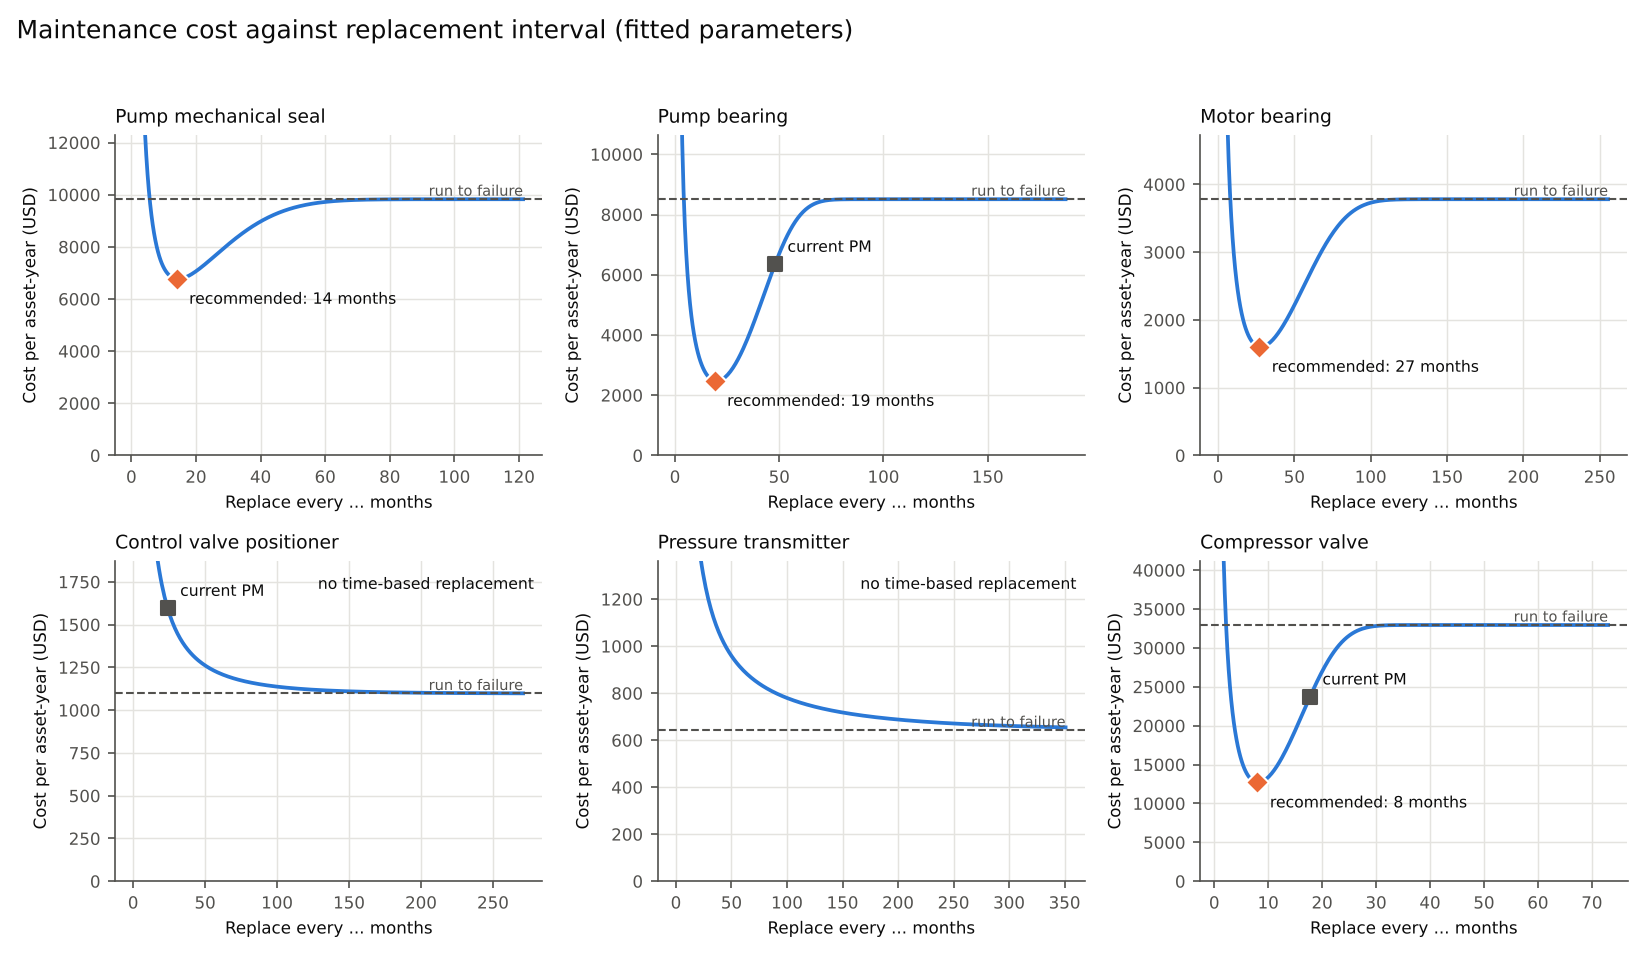

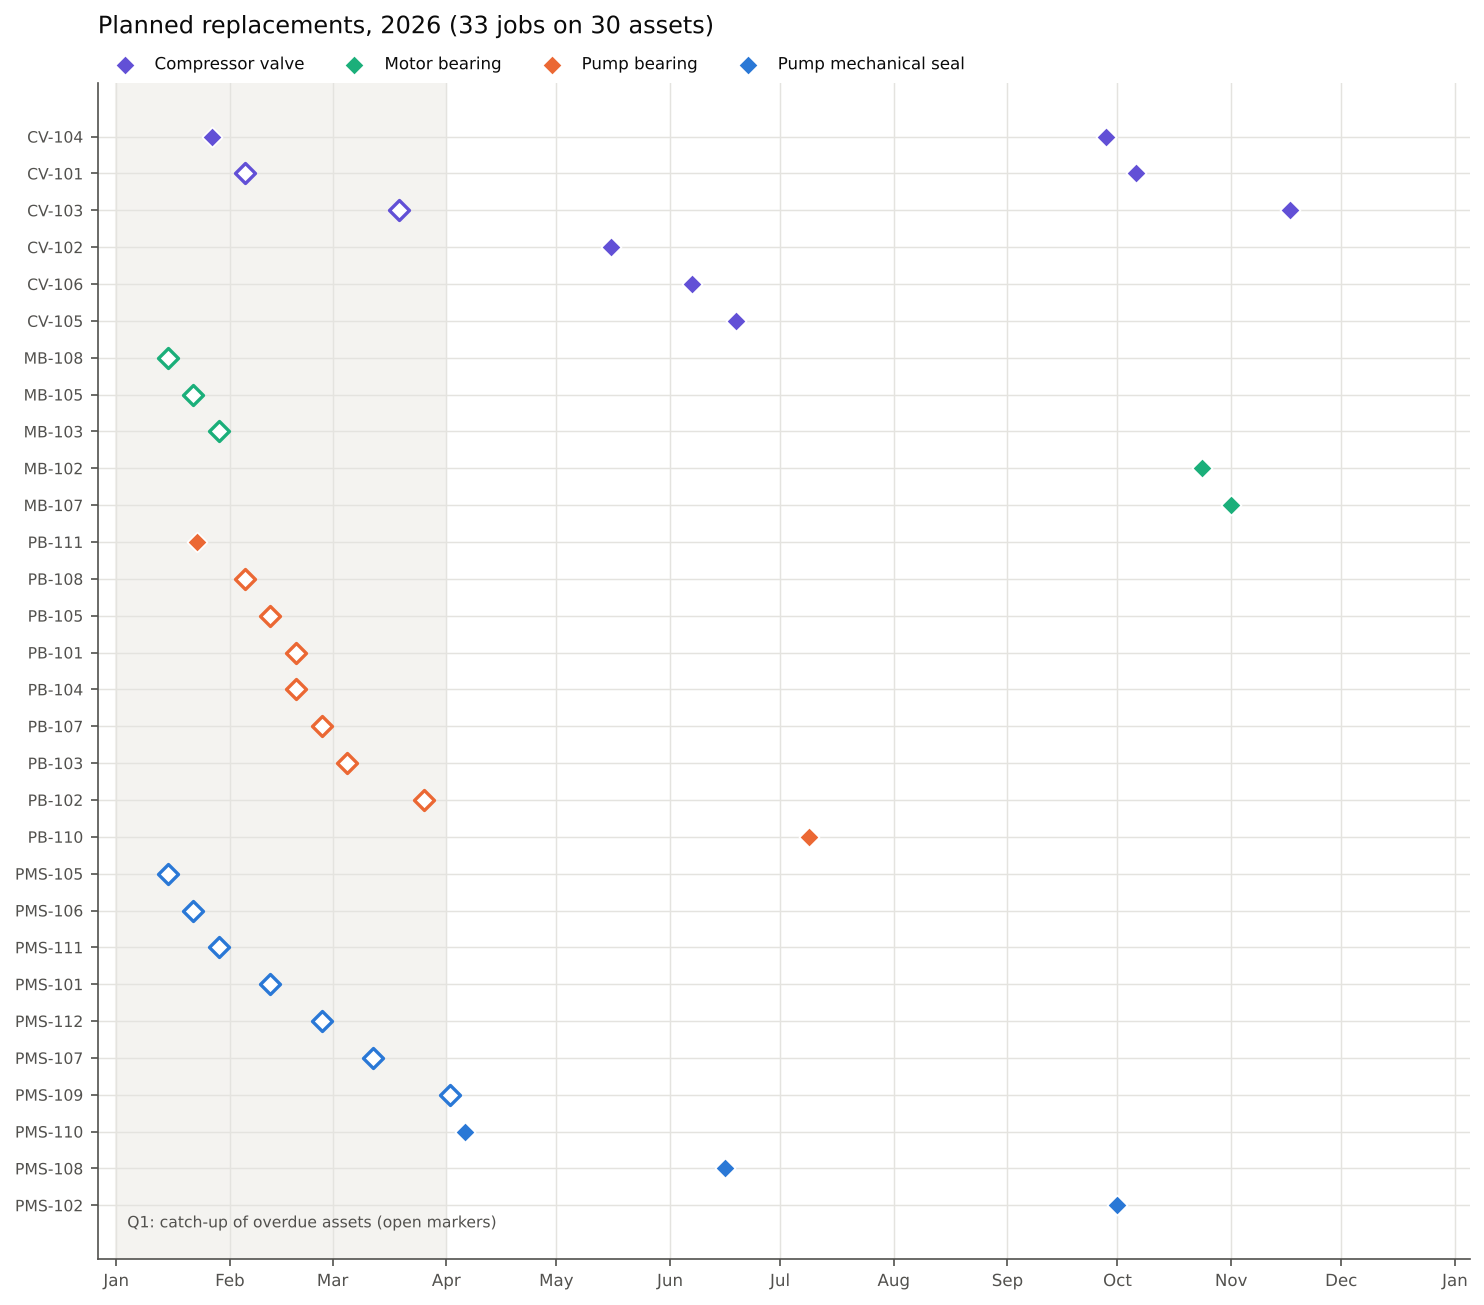

In [10]:
from src.utils import plots
plots.draw(summary, iv, plan, truth)
from IPython.display import Image, display
for f in ['weibull_fits', 'cost_curves', 'pm_schedule_2026']:
    display(Image(f'reports/figures/{f}.png', width=760))

## Serve it
`uvicorn src.api.app:app --reload`, then open http://127.0.0.1:8000/docs. The same call from Python, using the compressor-valve history:

In [11]:
from fastapi.testclient import TestClient
from src.api.app import app
g = iv[iv.equipment_class == 'Compressor valve']
body = dict(intervals=[dict(days=float(d), failed=bool(f)) for d, f in zip(g.days, g.failed)], planned_cost_usd=6000, failure_cost_usd=45000, current_pm_days=540)
TestClient(app).post('/fit', json=body).json()

{'failures': 21,
 'suspensions': 19,
 'crude_mtbf_days': 787,
 'crude_mtbf_90ci': [546, 1174],
 'weibull_beta': 3.37,
 'beta_90ci': [2.4, 4.56],
 'weibull_eta_days': 556,
 'mttf_days': 499,
 'strategy': 'Time-based replacement',
 'reason': 'wear-out (beta 3.37), saves 61% vs run-to-failure',
 'recommended_interval_months': 8,
 'fitted_cost_per_year_current_usd': 23698,
 'fitted_cost_per_year_recommended_usd': 12706}